# Structured LLM Extraction with Validation
**Use case:** turn messy hotel booking request emails into a clean, validated booking record using a small local LLM (`Qwen2.5-0.5B-Instruct`, CPU, no API keys).

**Schema (Pydantic `Booking`)**

| field | type / rule |
|---|---|
| `guest_name` | str (non-empty) |
| `check_in`, `check_out` | date or null, `check_out` > `check_in` |
| `num_guests` | int 1-10 or null |
| `room_type` | `single` / `double` / `suite` / `unknown` |
| `special_requests` | list[str], may be empty |
| `contact_email` | valid email or null |

**Pipeline**
```
email ─► prompt (system + schema + 1 example, greedy decoding)
      ─► LLM raw text
      ─► parse/repair (strip fences, first {...}, fix trailing commas / None)
      ─► Pydantic validation ──ok──► status = ok / ok_after_retry
              │ errors
              ▼
      retry (≤2) with "fix these errors, return only JSON"
              │ still failing
              ▼
      rule-based fallback (regex: email, dates, guests, room keywords) ─► status = fallback / failed
```

In [1]:
import json, time
import pandas as pd
import matplotlib.pyplot as plt
import extractor as ex
from extractor import extract, parse_json, parse_and_validate, rule_based_extract

print("Model:", ex.MODEL_ID, "| reference date:", ex.TODAY)

Model: Qwen/Qwen2.5-0.5B-Instruct | reference date: 2026-10-31


## 1. Sample emails
Clean ones plus tricky cases: missing dates, no guest count, weird date formats, and spam.

In [2]:
EMAILS = {
    "clean_1": """Hello, my name is Anna Schmidt. I would like to book a double room from 2026-12-10 to 2026-12-14 for 2 guests.
We would appreciate a sea view and breakfast included. Contact: anna.schmidt@example.com""",

    "clean_2": """Dear hotel team, this is Rahul Mehta. Please reserve a suite for 3 people, check-in 2027-01-05, check-out 2027-01-08.
We arrive late, so late check-in please, and we need airport transfer. My email is rahul.mehta@corp.in""",

    "clean_3": """Hi! Single room for one person please, 2026-11-20 until 2026-11-22. Quiet room if possible.
Thanks,
Lena Fischer
lena.f@web.de""",

    "missing_dates": """Hi, I'm Carlos Diaz. We are 4 people and want a suite sometime next spring, not sure about dates yet.
Is parking available? carlos.diaz@gmail.com""",

    "no_guest_count": """Good morning, my name is Yuki Tanaka. I need a double room from 2026-11-15 to 2026-11-18.
Please add an extra bed if possible. You can reach me at yuki.tanaka@mail.jp""",

    "weird_dates": """hey this is Mark Olsen, need a room 3rd of Dec to 7th of Dec 2026, two adults, double bed pls.
also a crib for the baby. mark.olsen@outlook.com""",

    "messy_slash_dates": """Booking request -- Name: Priya Nair -- arriving 24/12/2026 leaving 27/12/2026 -- 2 guests
room: SUITE!!! vegetarian breakfast. contact priya.nair@@mail.com (typo? use priya.nair@mail.com)""",

    "spam": """CONGRATULATIONS!!! You have been selected to receive a FREE iPhone. Click the link below to claim
your prize before it expires. Unsubscribe anytime.""",
}
print(len(EMAILS), "emails")

8 emails


## 2. Run the extractor on all emails
For each email: input, raw model output (every attempt), final JSON, status.

In [3]:
results = {}
for name, email in EMAILS.items():
    t = time.time()
    r = extract(email)
    results[name] = r
    print("=" * 100)
    print(f"[{name}]  status={r.status}  attempts={r.attempts}  ({time.time() - t:.1f}s)")
    print("--- input:\n" + email)
    for i, raw in enumerate(r.raw_outputs, 1):
        print(f"--- raw model output (attempt {i}):\n{raw}")
    if r.errors:
        print("--- errors:", *r.errors, sep="\n  ")
    print("--- final JSON:\n" + json.dumps(r.data, indent=2))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[clean_1]  status=ok  attempts=1  (15.7s)
--- input:
Hello, my name is Anna Schmidt. I would like to book a double room from 2026-12-10 to 2026-12-14 for 2 guests.
We would appreciate a sea view and breakfast included. Contact: anna.schmidt@example.com
--- raw model output (attempt 1):
{"guest_name": "Anna Schmidt", "check_in": "2026-12-10", "check_out": "2026-12-14", "num_guests": 2, "room_type": "double", "special_requests": ["sea view", "breakfast included"], "contact_email": "anna.schmidt@example.com"}
--- final JSON:
{
  "guest_name": "Anna Schmidt",
  "check_in": "2026-12-10",
  "check_out": "2026-12-14",
  "num_guests": 2,
  "room_type": "double",
  "special_requests": [
    "sea view",
    "breakfast included"
  ],
  "contact_email": "anna.schmidt@example.com"
}


[clean_2]  status=ok  attempts=1  (10.4s)
--- input:
Dear hotel team, this is Rahul Mehta. Please reserve a suite for 3 people, check-in 2027-01-05, check-out 2027-01-08.
We arrive late, so late check-in please, and we need airport transfer. My email is rahul.mehta@corp.in
--- raw model output (attempt 1):
{"guest_name": "Rahul Mehta", "check_in": "2027-01-05", "check_out": "2027-01-08", "num_guests": 3, "room_type": "suite", "special_requests": ["late check-in", "airport transfer"], "contact_email": "rahul.mehta@corp.in"}
--- final JSON:
{
  "guest_name": "Rahul Mehta",
  "check_in": "2027-01-05",
  "check_out": "2027-01-08",
  "num_guests": 3,
  "room_type": "suite",
  "special_requests": [
    "late check-in",
    "airport transfer"
  ],
  "contact_email": "rahul.mehta@corp.in"
}


[clean_3]  status=ok  attempts=1  (10.1s)
--- input:
Hi! Single room for one person please, 2026-11-20 until 2026-11-22. Quiet room if possible.
Thanks,
Lena Fischer
lena.f@web.de
--- raw model output (attempt 1):
{"guest_name": "Lena Fischer", "check_in": "2026-11-20", "check_out": "2026-11-22", "num_guests": 1, "room_type": "single", "special_requests": ["quiet room"], "contact_email": "lena.f@web.de"}
--- final JSON:
{
  "guest_name": "Lena Fischer",
  "check_in": "2026-11-20",
  "check_out": "2026-11-22",
  "num_guests": 1,
  "room_type": "single",
  "special_requests": [
    "quiet room"
  ],
  "contact_email": "lena.f@web.de"
}


[missing_dates]  status=ok  attempts=1  (8.1s)
--- input:
Hi, I'm Carlos Diaz. We are 4 people and want a suite sometime next spring, not sure about dates yet.
Is parking available? carlos.diaz@gmail.com
--- raw model output (attempt 1):
{"guest_name": "Carlos Diaz", "check_in": null, "check_out": null, "num_guests": 4, "room_type": "suite", "special_requests": [], "contact_email": "carlos.diaz@gmail.com"}
--- final JSON:
{
  "guest_name": "Carlos Diaz",
  "check_in": null,
  "check_out": null,
  "num_guests": 4,
  "room_type": "suite",
  "special_requests": [],
  "contact_email": "carlos.diaz@gmail.com"
}


[no_guest_count]  status=ok  attempts=1  (10.8s)
--- input:
Good morning, my name is Yuki Tanaka. I need a double room from 2026-11-15 to 2026-11-18.
Please add an extra bed if possible. You can reach me at yuki.tanaka@mail.jp
--- raw model output (attempt 1):
{"guest_name": "Yuki Tanaka", "check_in": "2026-11-15", "check_out": "2026-11-18", "num_guests": 2, "room_type": "double", "special_requests": ["extra bed"], "contact_email": "yuki.tanaka@mail.jp"}
--- final JSON:
{
  "guest_name": "Yuki Tanaka",
  "check_in": "2026-11-15",
  "check_out": "2026-11-18",
  "num_guests": 2,
  "room_type": "double",
  "special_requests": [
    "extra bed"
  ],
  "contact_email": "yuki.tanaka@mail.jp"
}


[weird_dates]  status=ok  attempts=1  (11.1s)
--- input:
hey this is Mark Olsen, need a room 3rd of Dec to 7th of Dec 2026, two adults, double bed pls.
also a crib for the baby. mark.olsen@outlook.com
--- raw model output (attempt 1):
{"guest_name": "Mark Olsen", "check_in": "2026-12-03", "check_out": "2026-12-07", "num_guests": 2, "room_type": "double", "special_requests": ["crib for the baby"], "contact_email": "mark.olsen@outlook.com"}
--- final JSON:
{
  "guest_name": "Mark Olsen",
  "check_in": "2026-12-03",
  "check_out": "2026-12-07",
  "num_guests": 2,
  "room_type": "double",
  "special_requests": [
    "crib for the baby"
  ],
  "contact_email": "mark.olsen@outlook.com"
}


[messy_slash_dates]  status=ok_after_retry  attempts=2  (24.6s)
--- input:
Booking request -- Name: Priya Nair -- arriving 24/12/2026 leaving 27/12/2026 -- 2 guests
room: SUITE!!! vegetarian breakfast. contact priya.nair@@mail.com (typo? use priya.nair@mail.com)
--- raw model output (attempt 1):
{"guest_name": "Priya Nair", "check_in": "2026-12-24", "check_out": "2026-12-27", "num_guests": 2, "room_type": "SUITE", "special_requests": ["vegetarian breakfast"], "contact_email": "priya.nair@mail.com"}
--- raw model output (attempt 2):
```json
{"guest_name": "Priya Nair", "check_in": "2026-12-24", "check_out": "2026-12-27", "num_guests": 2, "room_type": "unknown", "special_requests": ["vegetarian breakfast"], "contact_email": "priya.nair@mail.com"}
```
--- errors:
  attempt 1: room_type: Input should be 'single', 'double', 'suite' or 'unknown'
--- final JSON:
{
  "guest_name": "Priya Nair",
  "check_in": "2026-12-24",
  "check_out": "2026-12-27",
  "num_guests": 2,
  "room_type": "unknown"

[spam]  status=failed  attempts=1  (6.1s)
--- input:
CONGRATULATIONS!!! You have been selected to receive a FREE iPhone. Click the link below to claim
your prize before it expires. Unsubscribe anytime.
--- raw model output (attempt 1):
{"not_booking": true}
--- errors:
  model says this is not a booking request
--- final JSON:
null


## 3. Failure-handling demo (deterministic)
Hand-made bad model outputs are fed straight into the parser / validator, so this part does not depend on the LLM.

In [4]:
BAD_OUTPUTS = {
    "broken JSON (trailing comma, None)": '{"guest_name": "Ana Lopez", "check_in": "2026-12-01", "check_out": "2026-12-03", "num_guests": 2, "room_type": "double", "special_requests": [], "contact_email": None,}',
    "JSON wrapped in text + fences": 'Sure! Here is the booking:\n```json\n{"guest_name": "Ana Lopez", "check_in": "2026-12-01", "check_out": "2026-12-03", "num_guests": 2, "room_type": "double", "special_requests": ["sea view"], "contact_email": "ana@lopez.es"}\n```\nLet me know if you need anything else.',
    "truncated output": '{"guest_name": "Ana Lopez", "check_in": "2026-12-01", "check_out": "2026-12-03", "num_guests": 2, "room_type": "double", "special_requests": ["sea view"]',
    "wrong types": '{"guest_name": "Ana Lopez", "check_in": "first of December", "check_out": "2026-12-03", "num_guests": "a couple", "room_type": "double", "special_requests": "sea view", "contact_email": "ana-at-lopez"}',
    "check_out before check_in": '{"guest_name": "Ana Lopez", "check_in": "2026-12-05", "check_out": "2026-12-01", "num_guests": 2, "room_type": "double", "special_requests": [], "contact_email": null}',
    "unexpected room type": '{"guest_name": "Ana Lopez", "check_in": "2026-12-01", "check_out": "2026-12-03", "num_guests": 2, "room_type": "penthouse", "special_requests": [], "contact_email": null}',
    "no JSON at all": "I'm sorry, I cannot help with that request.",
}
rows = []
for case, raw in BAD_OUTPUTS.items():
    data, errs = parse_and_validate(raw)
    rows.append({"case": case, "valid": data is not None, "errors": "; ".join(errs) or "-"})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows)

,case,valid,errors
0,"broken JSON (trailing comma, None)",True,-
1,JSON wrapped in text + fences,True,-
2,truncated output,True,-
3,wrong types,False,"check_in: Input should be a valid date or datetime, invalid character in year; num_guests: Input should be a valid i..."
4,check_out before check_in,False,"booking: Value error, check_out must be after check_in"
5,unexpected room type,False,"room_type: Input should be 'single', 'double', 'suite' or 'unknown'"
6,no JSON at all,False,no JSON object found in model output


### Retry and fallback with a scripted "LLM"
A fake LLM returns pre-defined outputs in order, so we can deterministically show (a) a successful retry and (b) a fallback after all retries fail.
The second call also shows the error-feedback prompt the real model would receive.

In [5]:
def scripted_llm(outputs):
    it = iter(outputs)
    def llm(messages):
        llm.last_messages = messages
        return next(it)
    return llm

demo_email = EMAILS["clean_1"]
good = '{"guest_name": "Anna Schmidt", "check_in": "2026-12-10", "check_out": "2026-12-14", "num_guests": 2, "room_type": "double", "special_requests": ["sea view", "breakfast"], "contact_email": "anna.schmidt@example.com"}'

# (a) first output is invalid (check_out before check_in), second is fixed -> ok_after_retry
llm_a = scripted_llm([BAD_OUTPUTS["check_out before check_in"], good])
r = extract(demo_email, llm=llm_a)
print("(a) status:", r.status, "| attempts:", r.attempts, "| errors:", r.errors)
print("    feedback sent to model:\n   ", llm_a.last_messages[-1]["content"].replace("\n", "\n    "))

# (b) three bad outputs -> rule-based fallback
r = extract(demo_email, llm=scripted_llm([BAD_OUTPUTS["no JSON at all"], BAD_OUTPUTS["wrong types"], BAD_OUTPUTS["unexpected room type"]]))
print("\n(b) status:", r.status, "| attempts:", r.attempts)
print("    errors:", *r.errors, sep="\n      ")
print("    fallback data:", json.dumps(r.data, indent=2))

# (c) spam email with bad outputs -> fallback finds nothing -> failed
r = extract(EMAILS["spam"], llm=scripted_llm(["???"] * 3))
print("\n(c) spam status:", r.status, "| errors:", r.errors[-1])

(a) status: ok_after_retry | attempts: 2 | errors: ['attempt 1: booking: Value error, check_out must be after check_in']
    feedback sent to model:
    Your JSON had these errors:
    - booking: Value error, check_out must be after check_in
    Fix these errors and return only the corrected JSON.

(b) status: fallback | attempts: 3
    errors:
      attempt 1: no JSON object found in model output
      attempt 2: check_in: Input should be a valid date or datetime, invalid character in year
      attempt 2: num_guests: Input should be a valid integer, unable to parse string as an integer
      attempt 2: special_requests: Input should be a valid list
      attempt 2: contact_email: value is not a valid email address: An email address must have an @-sign.
      attempt 3: room_type: Input should be 'single', 'double', 'suite' or 'unknown'
    fallback data: {
  "guest_name": "Anna Schmidt",
  "check_in": "2026-12-10",
  "check_out": "2026-12-14",
  "num_guests": 2,
  "room_type": "doubl

### Rule-based extractor alone on every email (for comparison)

In [6]:
pd.DataFrame([{"email": n, **rule_based_extract(e)} for n, e in EMAILS.items()])

,email,guest_name,check_in,check_out,num_guests,room_type,special_requests,contact_email
0,clean_1,Anna Schmidt,2026-12-10,2026-12-14,2.0,double,"[breakfast, sea view]",anna.schmidt@example.com
1,clean_2,Rahul Mehta,2027-01-05,2027-01-08,3.0,suite,"[late check-in, airport transfer]",rahul.mehta@corp.in
2,clean_3,Lena Fischer,2026-11-20,2026-11-22,1.0,single,[quiet],lena.f@web.de
3,missing_dates,Carlos Diaz,NaN,NaN,4.0,suite,[parking],carlos.diaz@gmail.com
4,no_guest_count,Yuki Tanaka,2026-11-15,2026-11-18,NaN,double,[extra bed],yuki.tanaka@mail.jp
5,weird_dates,Mark Olsen,2026-12-03,2026-12-07,2.0,double,[crib],mark.olsen@outlook.com
6,messy_slash_dates,Priya Nair,2026-12-24,2026-12-27,2.0,suite,"[breakfast, vegetarian]",priya.nair@mail.com
7,spam,unknown,NaN,NaN,NaN,unknown,[],NaN


## 4. Summary

In [7]:
STATUSES = ["ok", "ok_after_retry", "fallback", "failed"]
summary = pd.DataFrame([{"email": n, "status": r.status, "attempts": r.attempts,
                         "guest_name": (r.data or {}).get("guest_name"),
                         "check_in": (r.data or {}).get("check_in"), "check_out": (r.data or {}).get("check_out"),
                         "num_guests": (r.data or {}).get("num_guests"), "room_type": (r.data or {}).get("room_type")}
                        for n, r in results.items()])
display(summary)
counts = summary["status"].value_counts().reindex(STATUSES, fill_value=0)
print(counts.to_string())
print("avg attempts:", round(summary["attempts"].mean(), 2))

,email,status,attempts,guest_name,check_in,check_out,num_guests,room_type
0,clean_1,ok,1,Anna Schmidt,2026-12-10,2026-12-14,2.0,double
1,clean_2,ok,1,Rahul Mehta,2027-01-05,2027-01-08,3.0,suite
2,clean_3,ok,1,Lena Fischer,2026-11-20,2026-11-22,1.0,single
3,missing_dates,ok,1,Carlos Diaz,NaN,NaN,4.0,suite
4,no_guest_count,ok,1,Yuki Tanaka,2026-11-15,2026-11-18,2.0,double
5,weird_dates,ok,1,Mark Olsen,2026-12-03,2026-12-07,2.0,double
6,messy_slash_dates,ok_after_retry,2,Priya Nair,2026-12-24,2026-12-27,2.0,unknown
7,spam,failed,1,NaN,NaN,NaN,NaN,NaN


status
ok                6
ok_after_retry    1
fallback          0
failed            1
avg attempts: 1.12


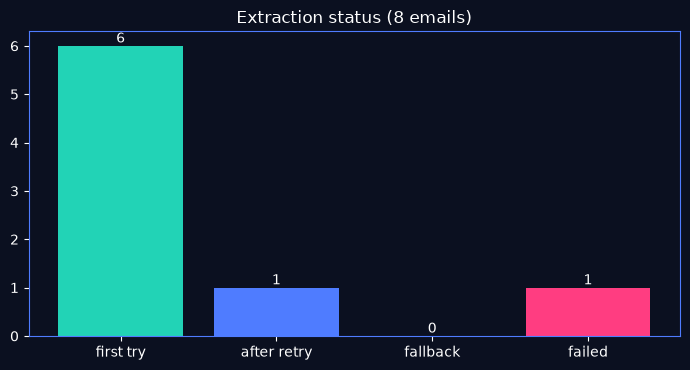

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8), facecolor="#0B1020")
ax.set_facecolor("#0B1020")
bars = ax.bar(["first try", "after retry", "fallback", "failed"], counts.values,
              color=["#22D3B6", "#4F7CFF", "#FFB020", "#FF3D81"])
ax.bar_label(bars, color="white")
ax.set_title("Extraction status (8 emails)", color="white")
ax.tick_params(colors="white")
for s in ax.spines.values():
    s.set_color("#4F7CFF")
plt.tight_layout()
plt.show()

## 5. Observations & limitations
- **Clean emails work first try:** the 0.5B model produced valid JSON for all 7 booking emails on attempt 1 (6 valid straight away); greedy decoding plus a single example keeps the format stable.
- **Normalisation is a weak spot:** for `messy_slash_dates` the model copied `"SUITE"` verbatim, which failed the enum check. The retry fixed the *format* but picked `"unknown"`, so the fix passes validation yet throws away information. Validation guarantees structure, not correctness.
- **Hallucination on missing fields:** for `no_guest_count` the model guessed `num_guests: 2` (probably from "double room") instead of null. Schema validation cannot catch a plausible guess like this.
- **Missing dates handled well:** the model returned null dates for "sometime next spring", and the schema accepts that. It did, however, drop the parking question from `special_requests`.
- **Spam is rejected explicitly:** the `{"not_booking": true}` escape hatch lets the model say "not applicable" instead of inventing a booking; the fallback also returns `failed` when it finds no booking signals.
- **The parser repairs the cheap failures** (code fences, chatter around the JSON, trailing commas, `None`, truncated output) without spending an LLM call. Real schema errors go to a retry, and the regex fallback recovered a full record in the scripted demo.

**Limitations:** only 8 hand-written emails (not a benchmark); the fallback regexes are English-only and assume DD/MM/YYYY; yearless dates depend on a fixed reference date; ~5-20 s per call on CPU; a retry can "fix" a value by blanking it out; there is no check that extracted values actually appear in the email (a grounding check would catch hallucinated guest counts).